# 15 · Drying and evaporation

Removing water is the most common and most energy-hungry separation: evaporators concentrate solutions
before crystallisation, dryers finish solids. Both are governed by heat transfer and by the properties of
moist air and steam. This notebook works through psychrometry, drying-rate curves and drying times, then
single- and multiple-effect evaporators with their steam economy - and shows why reusing vapour matters.

**What you will learn**
- use psychrometric relations
- analyse drying-rate curves and compute drying times
- design single- and multiple-effect evaporators
- account for the boiling-point rise

**Before you start:** notebook 00  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import datasets
from engsep import drying_evaporation as de
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Psychrometry: the air that does the drying

In [2]:
for T_C, RH in ((20.0, 0.6), (40.0, 0.2), (60.0, 0.05), (80.0, 0.02)):
    H = RH * de.humidity_saturation(T_C)
    print(f"air at {T_C:.0f} degC, {RH:.0%} RH: H = {H:.4f} kg/kg, dew point {de.dew_point(H):.1f} degC, wet-bulb {de.wet_bulb_temperature(T_C, H):.1f} degC, enthalpy {de.enthalpy_moist_air(T_C, H)/1e3:.0f} kJ/kg dry air")

air at 20 degC, 60% RH: H = 0.0088 kg/kg, dew point 12.2 degC, wet-bulb 15.2 degC, enthalpy 42 kJ/kg dry air
air at 40 degC, 20% RH: H = 0.0097 kg/kg, dew point 13.7 degC, wet-bulb 22.4 degC, enthalpy 65 kJ/kg dry air
air at 60 degC, 5% RH: H = 0.0076 kg/kg, dew point 10.0 degC, wet-bulb 26.3 degC, enthalpy 80 kJ/kg dry air
air at 80 degC, 2% RH: H = 0.0109 kg/kg, dew point 15.4 degC, wet-bulb 32.3 degC, enthalpy 109 kJ/kg dry air


Hot dry air has a low wet-bulb temperature: the surface of a wet solid sits at the wet-bulb temperature while
water evaporates freely, whatever the air temperature, so heating the air raises the driving force
($T - T_{wb}$) without cooking the product. That is the whole thermodynamic reason for hot-air drying.

## The drying-rate curve

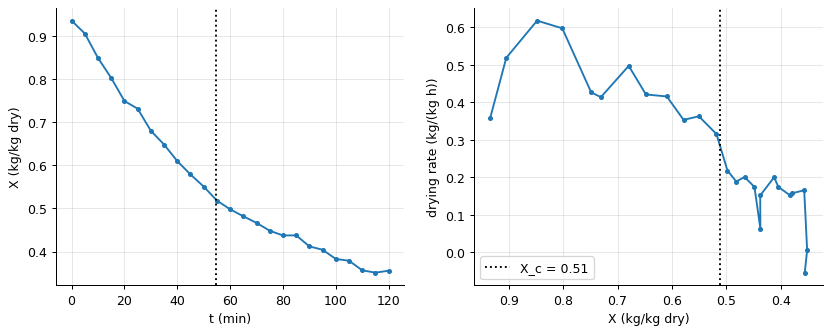

constant rate 0.447 kg/(kg h) until the critical moisture X_c = 0.51; then the rate falls


In [3]:
d = pd.read_csv(datasets.path("drying_curve.csv"), comment="#")
an = de.drying_curve_analysis(d.t_s, d.X_dry_basis)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(d.t_s / 60, d.X_dry_basis, "o-", ms=3); ax[0].axvline(an["t_critical"] / 60, color="k", ls=":"); ax[0].set(xlabel="t (min)", ylabel="X (kg/kg dry)")
ax[1].plot(d.X_dry_basis, an["rate"] * 3600, "o-", ms=3); ax[1].axvline(an["X_critical"], color="k", ls=":", label=f"X_c = {an['X_critical']:.2f}"); ax[1].set(xlabel="X (kg/kg dry)", ylabel="drying rate (kg/(kg h))"); ax[1].invert_xaxis(); ax[1].legend(); plt.show()
print(f"constant rate {an['R_c']*3600:.3f} kg/(kg h) until the critical moisture X_c = {an['X_critical']:.2f}; then the rate falls")

While the surface is wet the rate is constant and set by the air (heat transfer to a wet-bulb surface);
once the surface dries out - at the critical moisture content - water must diffuse from inside and the rate
falls, roughly in proportion to the free moisture. The two regimes need different scale-up: the first
depends on air velocity and temperature, the second on the solid's thickness and structure.

## Drying time

In [4]:
X0, X_final, X_c, X_eq = 0.9, 0.10, an["X_critical"], 0.06
R_c = an["R_c"]
dt = de.drying_time(X0, X_final, X_c, X_eq, R_c, A_over_ms=1.0)
print(f"from X = {X0} to {X_final}: constant-rate period {dt['t_constant']/60:.0f} min, falling-rate period {dt['t_falling']/60:.0f} min, total {dt['t_total']/60:.0f} min")
for X_f in (0.2, 0.1, 0.07):
    print(f"drying to X = {X_f}: {de.drying_time(X0, X_f, X_c, X_eq, R_c, 1.0)['t_total']/60:.0f} min")

from X = 0.9 to 0.1: constant-rate period 52 min, falling-rate period 147 min, total 199 min
drying to X = 0.2: 123 min
drying to X = 0.1: 199 min
drying to X = 0.07: 284 min


The falling-rate period takes longer than the constant one even though it removes less water, and the last
few percent towards the equilibrium moisture take forever: the log-mean dependence. Specifying a product
drier than it needs to be is the commonest waste in a drying operation.

## Single-effect evaporation

In [5]:
se = de.single_effect(feed_kg_s=2.0, x_feed=0.10, x_product=0.40, T_feed_C=25.0, T_boil_C=100.0, T_steam_C=120.0, U=2000.0, bpr=3.0)
print(f"2 kg/s of 10 % solution to 40 %: evaporates {se['vapour_kg_s']:.2f} kg/s, needs {se['steam_kg_s']:.2f} kg/s of steam (economy {se['economy']:.2f}), duty {se['Q_W']/1e6:.2f} MW, area {se['area_m2']:.0f} m2 at dT = {se['dT_driving']:.0f} K")

2 kg/s of 10 % solution to 40 %: evaporates 1.50 kg/s, needs 1.81 kg/s of steam (economy 0.83), duty 4.01 MW, area 118 m2 at dT = 17 K


A single effect evaporates less than a kilogram of water per kilogram of steam - the latent heat is simply
passed through, and heating a cold feed costs extra. The boiling-point rise of the concentrated solution eats
into the temperature difference, and the area follows from $Q = UA\,\Delta T$.

## Multiple effects: reusing the vapour

In [6]:
rows = []
for n in (1, 2, 3, 4):
    me = de.multiple_effect(n, 2.0, 0.10, 0.40, 95.0, 120.0, 55.0, [2500.0 - 300 * i for i in range(n)], bpr_list=[1.0 + 0.7 * i for i in range(n)])
    rows.append((n, me["steam_kg_s"], me["economy"], me["areas_m2"].sum(), np.round(me["T_boil_C"], 1)))
print(pd.DataFrame(rows, columns=["effects", "steam (kg/s)", "economy", "total area (m2)", "boiling temperatures (degC)"]).round(2).to_string(index=False))

 effects  steam (kg/s)  economy  total area (m2) boiling temperatures (degC)
       1          1.46     1.03            20.26                      [55.0]
       2          0.73     2.04            45.09                [90.1, 55.0]
       3          0.50     3.02            76.36         [101.7, 81.4, 55.0]
       4          0.38     3.93           117.88   [107.5, 94.4, 77.3, 55.0]


The vapour from one effect boils the next at a lower pressure, so one kilogram of steam evaporates nearly
$n$ kilograms in $n$ effects: the economy climbs and the steam bill falls. The price is area - the same total
temperature drop is split among the effects, so each works with a smaller $\Delta T$ and the total area grows
roughly in proportion to $n$. Sugar mills run five or six effects; the optimum number is where the saved
steam stops paying for the extra steel.

## The boiling-point rise

In [7]:
for bpr in (0.0, 5.0, 15.0):
    me = de.multiple_effect(3, 2.0, 0.10, 0.40, 95.0, 120.0, 55.0, [2500.0, 2200.0, 1900.0], bpr_list=[bpr / 3, bpr / 2, bpr])
    print(f"boiling-point rise up to {bpr:.0f} K: economy {me['economy']:.2f}, total area {me['areas_m2'].sum():.0f} m2")

boiling-point rise up to 0 K: economy 3.05, total area 70 m2
boiling-point rise up to 5 K: economy 2.99, total area 82 m2
boiling-point rise up to 15 K: economy 2.88, total area 123 m2


A concentrated solution boils above pure water, and that rise is lost driving force in every effect: with a
large rise (caustic soda, some sugar liquors) the effects run out of temperature difference and the area
balloons. Boiling-point rise is the reason some solutions are concentrated in two or three effects when
economics alone would ask for six.

## Inside the algorithm: the falling-rate time

In [8]:
print(f"by hand: {(X_c - X_eq) / (R_c * 1.0) * np.log((X_c - X_eq) / (X_final - X_eq)) / 60:.6g} min; library: {dt['t_falling'] / 60:.6g}")

by hand: 147.266 min; library: 147.266


## Exercises
1. The cake is dried with air at 80 degC instead of 60 (same humidity): estimate the new constant rate from the wet-bulb driving force (R_c proportional to T - T_wb) and the new drying time to X = 0.10. What about the falling-rate period - does hotter air help there?
2. Backward feed: in a triple effect, feed the cold solution to the last (coldest) effect and pump it towards the first. Argue, with the single-effect function applied effect by effect, why backward feed gives a better economy for a cold feed and a viscous concentrate.
3. **Implement it yourself:** write the single-effect balance yourself (vapour from the concentration ratio, duty from sensible + latent heat, steam from the latent heat at the steam temperature) and reproduce `single_effect`.